# Rosella sizing: results and manual configuration

This notebook reads the result files of `tools/aerosandbox/rosella.py`. It plots them. It also has a window where you type your own parts and check them against every constraint.

The notebook reads `work/aerosandbox/rosella/sizing/` and writes plots to `work/aerosandbox/rosella/lab/`. It never writes the source tree (ADR 14). The Save button writes one machine file: `tools/aerosandbox/settings/rosella.manual.json`.

Frame: x aft, y right, z up. Units: metres, kilograms, seconds, unless a label says otherwise.

If a result file does not hold a datum, the plot is skipped. A note says which key is missing.

In [13]:
import sys, json, math, copy, warnings
sys.path.insert(0, "..")                    # tools/aerosandbox: lab.py and rosella.py
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
import plotly.graph_objects as go
import lab, rosella

lab.style()
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
pd.set_option("display.width", 200)
SIZING = rosella.WORK / "sizing"            # read only
OUT = rosella.WORK / "lab"                  # all plots go here
OUT.mkdir(parents=True, exist_ok=True)
MANUAL = rosella.HERE / "settings" / "rosella.manual.json"
ST = rosella.settings()
MISSING = []                                # keys that the result files do not hold

def note(msg):
    MISSING.append(msg)
    display(Markdown(f"**Skipped.** {msg}"))

def have(rep, *keys):
    """True when every key exists. Else it prints a note and returns False."""
    gone = [k for k in keys if k not in rep]
    if gone:
        note("The result file has no key " + ", ".join(f"`{k}`" for k in gone) + ".")
    return not gone

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")

## Step 1. Load the results

Each case file is one config and one cell count. `best.json` wraps the best case: `{case, level, result}`. A background run can replace a file while you read it. The loader skips a file that it cannot parse.

In [14]:
def load_cases():
    cases = {}
    for f in sorted(SIZING.glob("H*_*S.json")):
        try:
            cases[f.stem] = json.loads(f.read_text(encoding="utf-8"))
        except (ValueError, OSError):
            print("skipped (being written):", f.name)
    return cases

CASES = load_cases()
_b = json.loads((SIZING / "best.json").read_text(encoding="utf-8"))
BEST_NAME = _b.get("case", "best")
BEST = _b.get("result", _b)
print("cases:", list(CASES))
print("best:", BEST_NAME, "level", BEST.get("level_reached"), "E", round(BEST["energy_total_Wh"], 1), "Wh, M", round(BEST["names"]["M"], 2), "kg")
print("keys:", sorted(BEST))

cases: ['H4_10S', 'H4_12S', 'H4_14S', 'H4_6S', 'H4_8S', 'H8_10S', 'H8_12S', 'H8_14S', 'H8_6S', 'H8_8S']
best: H4_10S level L4 E 337.2 Wh, M 13.99 kg
keys: ['D_m', 'I_battery_max_A', 'P_battery_W', 'R_m', 'V_bus_max_V', 'active', 'airframe', 'attempts', 'boom_material', 'boom_z_m', 'c_ref_m', 'cda_m2', 'cells_s', 'config', 'constraints', 'control', 'converged', 'cruise', 'design', 'energy_Wh', 'energy_nominal_Wh', 'energy_total_Wh', 'error', 'f1_Hz', 'f_hover_1P_Hz', 'feasibility', 'feasibility_phase', 'gap_to_lower_level', 'inertia_kg_m2', 'infeasible', 'items', 'iterations', 'ladder_status', 'level', 'level_reached', 'motor_fit', 'multistart', 'names', 'ok', 'pitch_m', 'pitch_note', 'placeholders', 'rotor_z_m', 'rotors', 'seconds', 'settings_changed', 'slacks', 'spacing_m', 'status', 'status_word', 'structure', 'time_s']


In [15]:
# The fixed airframe (wing, tail, fuselage, neutral point). This takes a minute: it runs one VLM and one AeroBuildup sweep.
AIR = rosella.Airframe(ST)
MOTOR = rosella.MotorFit(rosella.HERE / "data" / "motor_survey.csv")
print(f"neutral point {AIR.neutral_point:.3f} m, MAC {AIR.c_ref:.3f} m, wing area {AIR.s_ref:.3f} m2")

neutral point 0.172 m, MAC 0.330 m, wing area 1.076 m2


## Step 2. Geometry: three views and a 3D view

The three views show the wing, tail, fuselage, the two booms, the rotor discs and every point mass. The marker area follows the mass. A cant angle is not drawn. For H8, the second disc of each pair sits 0.25 D above the first.

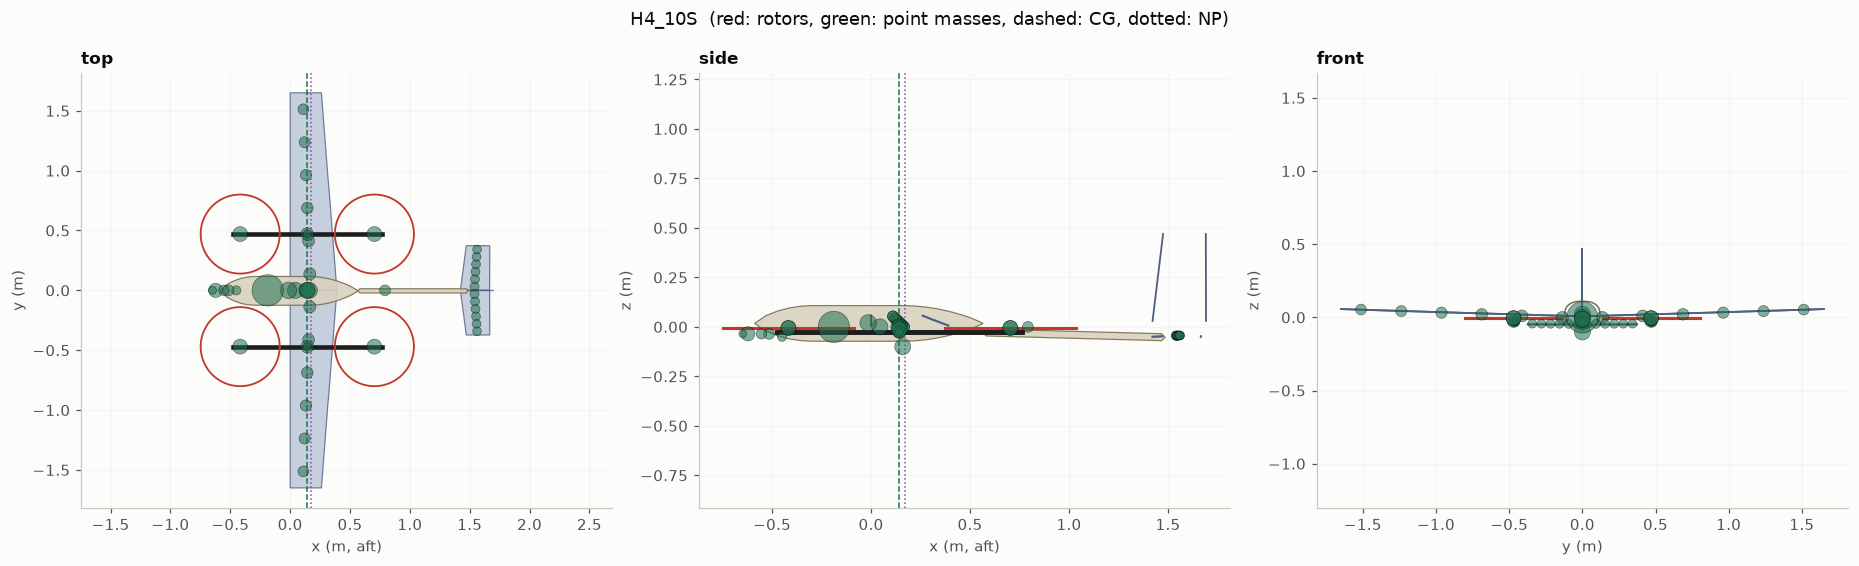

In [16]:
def geometry(rep):
    """Boom, rotor and point-mass numbers of one result, in the design frame."""
    d, n = rep["design"], rep["names"]
    z_b = rep.get("boom_z_m", AIR.tail_boom_z)        # the lift booms are level with the tail boom
    z_r = rep.get("rotor_z_m", z_b + rosella.val(ST["structure"], "mount_offset_m"))
    gap = rep.get("spacing_m") or 0.0
    R = rep["R_m"]
    rotors = []
    for side in (-1, 1):
        for x in (n["x_f"], n["x_r"]):
            rotors.append((x, side * d["y_b"], z_r))
            if rep["config"] == "H8":
                rotors.append((x, side * d["y_b"], z_r + gap))
    return dict(R=R, z_b=z_b, y_b=d["y_b"], x_c=n["x_c"], L=n["L_boom"], rotors=rotors)

def surface_lines(spec):
    """LE and TE points of a lifting surface (right side first, then the mirror)."""
    sec = spec["sections"]
    le = np.array([s["xyz_le"] for s in sec], float)
    te = le + np.array([[s["chord"], 0.0, 0.0] for s in sec])
    out = [(le, te)]
    if spec.get("mirror"):
        m = np.array([1.0, -1.0, 1.0])
        out.append((le * m, te * m))
    return out

def draw_views(rep, title=""):
    g = geometry(rep)
    items = rep.get("items", [])
    fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
    names = {"top": (0, 1, "x (m, aft)", "y (m)"), "side": (0, 2, "x (m, aft)", "z (m)"), "front": (1, 2, "y (m)", "z (m)")}
    for a, (view, (i, j, xl, yl)) in zip(ax, names.items()):
        for nm, spec in AIR.surfaces.items():
            for le, te in surface_lines(spec):
                if view == "top":
                    a.fill(np.r_[le[:, 0], te[::-1, 0]], np.r_[le[:, 1], te[::-1, 1]], color="#b8c4d6", ec="#506080", lw=0.8, alpha=0.8)
                else:
                    a.plot(le[:, i], le[:, j], color="#506080", lw=1.2)
                    a.plot(te[:, i], te[:, j], color="#506080", lw=1.2)
        for frames in (AIR.new_fuselage_frames(), AIR.tail_boom_frames):
            F = np.array(frames)                        # (stations, points, 3)
            x = F[:, 0, 0]
            if view == "top":
                w = F[:, :, 1].max(axis=1)
                a.fill_between(x, -w, w, color="#d9d2c0", ec="#7a6e50", lw=0.8, alpha=0.9)
            elif view == "side":
                a.fill_between(x, F[:, :, 2].min(axis=1), F[:, :, 2].max(axis=1), color="#d9d2c0", ec="#7a6e50", lw=0.8, alpha=0.9)
            else:
                k = int(np.argmax(F[:, :, 1].max(axis=1)))
                a.plot(F[k, :, 1], F[k, :, 2], color="#7a6e50", lw=1.0)
                a.plot(-F[k, :, 1], F[k, :, 2], color="#7a6e50", lw=1.0)
        for side in (-1, 1):                              # booms
            if view == "front":
                a.plot([side * g["y_b"]], [g["z_b"]], "o", color="#1d1d1d", ms=6)
            else:
                P = {"x": [g["x_c"] - g["L"] / 2, g["x_c"] + g["L"] / 2], "y": [side * g["y_b"]] * 2, "z": [g["z_b"]] * 2}
                a.plot(P["xyz"[i]], P["xyz"[j]], color="#1d1d1d", lw=3)
        for (x, y, z) in g["rotors"]:                      # rotor discs
            c, R = {"x": x, "y": y, "z": z}, g["R"]
            if view == "top":
                t = np.linspace(0, 2 * np.pi, 80)
                a.plot(x + R * np.cos(t), y + R * np.sin(t), color="#c0392b", lw=1.2)
            else:
                a.plot([c["xyz"[i]] - R, c["xyz"[i]] + R], [z, z], color="#c0392b", lw=2.0)
        if items:
            m = np.array([it["mass_kg"] for it in items]); P = np.array([[it["x"], it["y"], it["z"]] for it in items])
            a.scatter(P[:, i], P[:, j], s=20 + 400 * m / m.max(), c="#1f6f50", alpha=0.55, ec="k", lw=0.4, zorder=5)
        if "airframe" in rep and view != "front":
            a.axvline(rep["airframe"]["x_cg_m"], color="#1f6f50", ls="--", lw=1.0)
            a.axvline(rep["airframe"]["neutral_point_m"], color="#8e44ad", ls=":", lw=1.0)
        a.set_xlabel(xl); a.set_ylabel(yl); a.set_aspect("equal", adjustable="datalim"); a.grid(alpha=0.3); a.set_title(view)
    fig.suptitle(title or f"{rep['config']} {rep['cells_s']}S  (red: rotors, green: point masses, dashed: CG, dotted: NP)")
    fig.tight_layout()
    return fig

if have(BEST, "items", "design", "names", "R_m"):
    fig = draw_views(BEST, f"{BEST_NAME}  (red: rotors, green: point masses, dashed: CG, dotted: NP)")
    save(fig, "geometry_three_view"); plt.show()

In [17]:
def draw_3d(rep):
    g = geometry(rep)
    fig = AIR._build(fuselages=True).draw(backend="plotly", show=False)
    for side in (-1, 1):
        fig.add_trace(go.Scatter3d(x=[g["x_c"] - g["L"] / 2, g["x_c"] + g["L"] / 2], y=[side * g["y_b"]] * 2, z=[g["z_b"]] * 2,
                                   mode="lines", line=dict(color="black", width=8), name="boom", showlegend=side < 0))
    t = np.linspace(0, 2 * np.pi, 60)
    for k, (x, y, z) in enumerate(g["rotors"]):
        fig.add_trace(go.Scatter3d(x=x + g["R"] * np.cos(t), y=y + g["R"] * np.sin(t), z=np.full_like(t, z), mode="lines",
                                   line=dict(color="firebrick", width=4), name="rotor", showlegend=k == 0))
    items = rep["items"]
    mx = max(j["mass_kg"] for j in items)
    fig.add_trace(go.Scatter3d(x=[i["x"] for i in items], y=[i["y"] for i in items], z=[i["z"] for i in items], mode="markers",
                               marker=dict(size=[3 + 14 * i["mass_kg"] / mx for i in items], color="seagreen", opacity=0.7),
                               text=[f"{i['name']}  {1000 * i['mass_kg']:.0f} g" for i in items], hoverinfo="text", name="point masses"))
    if "airframe" in rep:
        a = rep["airframe"]
        fig.add_trace(go.Scatter3d(x=[a["x_cg_m"]], y=[0], z=[0], mode="markers", marker=dict(size=8, color="green", symbol="diamond"), name="CG"))
        fig.add_trace(go.Scatter3d(x=[a["neutral_point_m"]], y=[0], z=[0], mode="markers", marker=dict(size=8, color="purple", symbol="x"), name="NP"))
    fig.update_layout(scene=dict(aspectmode="data", xaxis_title="x (aft)", yaxis_title="y", zaxis_title="z"), height=650,
                      title=f"{BEST_NAME}: airframe, rotors, booms and point masses", margin=dict(l=0, r=0, t=40, b=0))
    return fig

if have(BEST, "items", "design", "names", "R_m"):
    f3 = draw_3d(BEST)
    f3.write_html(str(OUT / "geometry_3d.html"))
    f3.show()

## Step 3. Mass breakdown, CG, NP and static margin

The mass list comes from `items`. The CG check sums the list. The neutral point is from the vortex-lattice run of the airframe. The static margin is `(x_np - x_cg) / MAC`.

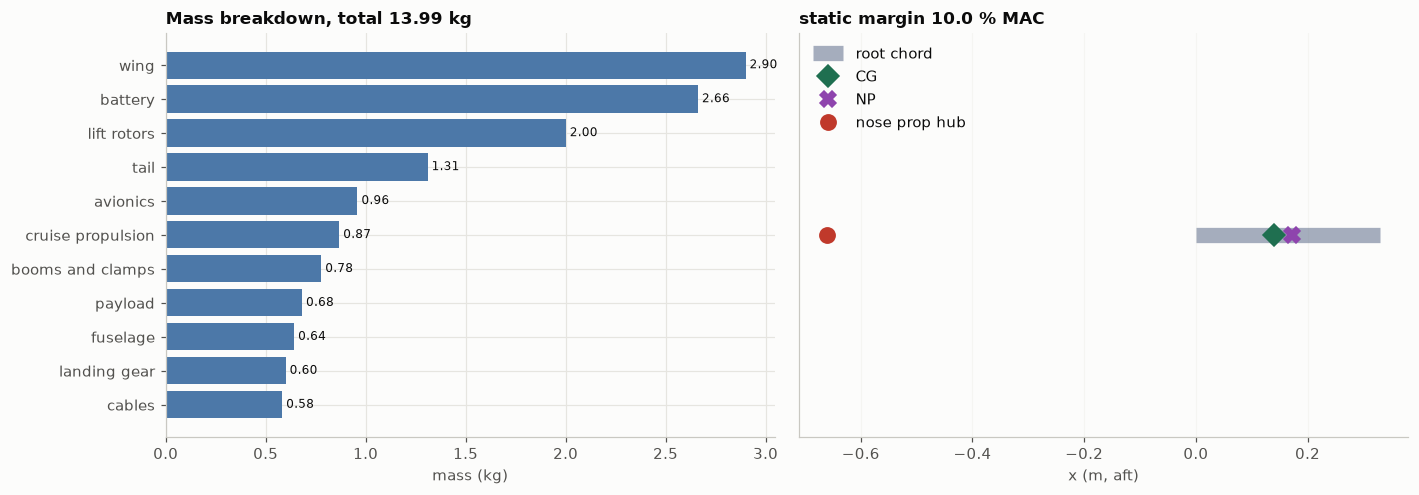

,value
M (kg),13.99
sum of items (kg),13.99
x_cg model (m),0.1391
x_cg from items (m),0.1391
x_np (m),0.1721
static margin (MAC),0.1
CG to nose prop (m),0.8


In [30]:
GROUP = {"wing": "wing", "tail": "tail", "tail_boom": "tail", "fuselage": "fuselage", "avionics": "avionics", "avionics_vtol": "avionics",
         "payload_cargo": "payload", "payload_camera": "payload", "landing_gear": "landing gear", "cruise_motor": "cruise propulsion",
         "cruise_esc": "cruise propulsion", "cruise_prop": "cruise propulsion", "cruise_rest": "cruise propulsion", "battery": "battery",
         "boom": "booms and clamps", "boom_clamp": "booms and clamps", "lift_front": "lift rotors", "lift_rear": "lift rotors", "cables": "cables"}

def mass_table(rep):
    df = pd.DataFrame(rep["items"])
    df["group"] = df["name"].map(GROUP).fillna(df["name"])
    return df

if have(BEST, "items", "airframe"):
    df = mass_table(BEST)
    grp = df.groupby("group")["mass_kg"].sum().sort_values()
    cg_items = float((df.mass_kg * df.x).sum() / df.mass_kg.sum())
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
    ax[0].barh(grp.index, grp.values, color="#4c78a8")
    for k, v in enumerate(grp.values):
        ax[0].text(v, k, f" {v:.2f}", va="center", fontsize=8)
    ax[0].set_xlabel("mass (kg)"); ax[0].set_title(f"Mass breakdown, total {df.mass_kg.sum():.2f} kg")
    a = BEST["airframe"]
    mac_le = float(AIR.le_x(0.0)); c = BEST.get("c_ref_m", AIR.c_ref)
    ax[1].hlines(0, mac_le, mac_le + c, color="#506080", lw=10, alpha=0.5, label="root chord")
    ax[1].plot(a["x_cg_m"], 0, "D", color="#1f6f50", ms=10, label="CG")
    ax[1].plot(a["neutral_point_m"], 0, "X", color="#8e44ad", ms=10, label="NP")
    ax[1].plot(a["x_nose_hub_m"], 0, "o", color="#c0392b", ms=10, label="nose prop hub")
    ax[1].set_ylim(-1, 1); ax[1].set_yticks([]); ax[1].set_xlabel("x (m, aft)"); ax[1].legend(loc="upper left"); ax[1].grid(alpha=0.3)
    sm = (a["neutral_point_m"] - a["x_cg_m"]) / c
    ax[1].set_title(f"static margin {100 * sm:.1f} % MAC")
    fig.tight_layout(); save(fig, "mass_cg_np"); plt.show()
    display(pd.Series({"M (kg)": BEST["names"]["M"], "sum of items (kg)": df.mass_kg.sum(), "x_cg model (m)": a["x_cg_m"],
                       "x_cg from items (m)": cg_items, "x_np (m)": a["neutral_point_m"], "static margin (MAC)": sm,
                       "CG to nose prop (m)": a["x_cg_m"] - a["x_nose_hub_m"]}, name="value").to_frame())

## Step 4. Inertia and control inputs

In [19]:
if have(BEST, "inertia_kg_m2", "control"):
    I = BEST["inertia_kg_m2"]; ctl = BEST["control"]
    display(pd.DataFrame({"value": {"Ixx (kg m2)": I["ixx"], "Iyy (kg m2)": I["iyy"], "Izz (kg m2)": I["izz"],
                                    "required angular acceleration (rad/s2)": ctl["alpha_req"], "bandwidth (rad/s)": ctl["w_bw"],
                                    "hub radius L_hub (m)": ctl["L_hub"]}}))

,value
Ixx (kg m2),3.039
Iyy (kg m2),3.931
Izz (kg m2),6.939
required angular acceleration (rad/s2),6.812
bandwidth (rad/s),5.703
hub radius L_hub (m),1.463


## Step 5. Mission energy for each segment

Each segment carries an energy-equivalent time (see `settings/rosella.yaml`, section `mission`). The nominal energy is the pack energy before the depth of discharge limit.

,E (Wh),t (s),P mean (W)
vtol_takeoff_climb,5.781,12,1734
transitions,12.2,30,1464
fw_climb,6.444,24.23,957.3
transit_laps_rtl,157.1,2042,276.9
survey,10.1,124.7,291.5
deploy_hover,22.98,60,1379
landing,7.661,20,1379
reserve,114.9,300,1379


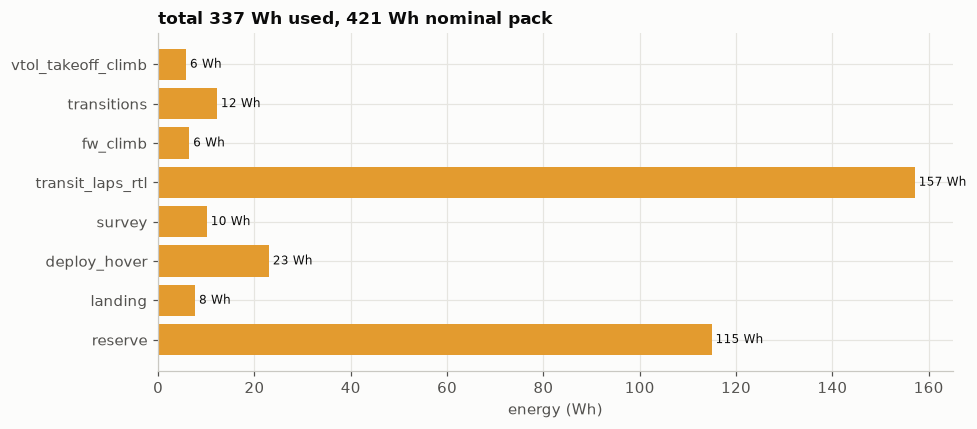

In [20]:
if have(BEST, "energy_Wh", "time_s", "energy_total_Wh"):
    e, t = BEST["energy_Wh"], BEST["time_s"]
    df = pd.DataFrame({"E (Wh)": e, "t (s)": t}); df["P mean (W)"] = df["E (Wh)"] * 3600 / df["t (s)"]
    display(df)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(list(e)[::-1], list(e.values())[::-1], color="#e39b2f")
    for k, v in enumerate(list(e.values())[::-1]):
        ax.text(v, k, f" {v:.0f} Wh", va="center", fontsize=8)
    ax.set_xlabel("energy (Wh)")
    ax.set_title(f"total {BEST['energy_total_Wh']:.0f} Wh used, {BEST.get('energy_nominal_Wh', float('nan')):.0f} Wh nominal pack")
    fig.tight_layout(); save(fig, "mission_energy"); plt.show()

## Step 6. H4 and H8 against S

One row for each case file. The margin column is the smallest margin of the enabled inequalities. A negative margin means a failed constraint. Equalities are not in this column.

,case,config,S,level,converged,E (Wh),M (kg),D (mm),kV,cap (Ah),y_b (m),min margin,worst
0,H4_6S,H4,6,L0,True,262.1,11.21,660.4,60,14.76,0.35,-4.185e-07,energy_Wh
1,H4_8S,H4,8,L4,True,358.5,14.68,660.4,227.9,15.14,0.4702,-6.641e-08,control_yaw_rad_s2
2,H4_10S,H4,10,L4,True,337.2,13.99,660.4,171.9,11.39,0.4702,-6.492e-08,control_yaw_rad_s2
3,H4_12S,H4,12,L1,True,292.8,12.48,660.4,132.2,8.244,0.35,6.35e-09,energy_Wh
4,H4_14S,H4,14,L3,True,316.7,13.28,660.4,115.7,7.643,0.4702,-6.43e-08,control_yaw_rad_s2
5,H8_6S,H8,6,L0,True,299,12.15,660.4,60,16.83,0.35,-4.21e-07,energy_Wh
6,H8_8S,H8,8,L3,True,391.3,14.99,619.4,181.7,16.52,0.4497,5.854e-08,energy_Wh
7,H8_10S,H8,10,L4,True,363.7,14.45,660.4,124.8,12.29,0.4702,-6.635e-08,control_yaw_rad_s2
8,H8_12S,H8,12,L3,True,367.3,14.14,611.7,117.4,10.34,0.4458,-8.007e-08,control_yaw_rad_s2
9,H8_14S,H8,14,L4,True,347.8,13.9,660.4,85.68,8.393,0.4702,3.961e-11,energy_Wh


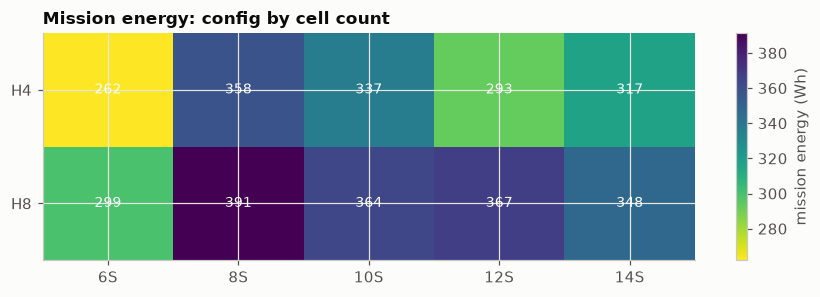

In [21]:
def summary(cases):
    rows = []
    for nm, r in cases.items():
        con = r.get("constraints", {})
        ineq = {k: v["margin"] for k, v in con.items() if v.get("enabled") and not v.get("equality")}
        wk = min(ineq, key=ineq.get) if ineq else ""
        rows.append({"case": nm, "config": r.get("config"), "S": r.get("cells_s"), "level": r.get("level_reached", r.get("level")),
                     "converged": r.get("converged"), "E (Wh)": r.get("energy_total_Wh"), "M (kg)": r.get("names", {}).get("M"),
                     "D (mm)": 1000 * r["D_m"] if "D_m" in r else 25.4 * r["D_in"] if "D_in" in r else None, "kV": r.get("design", {}).get("kv"), "cap (Ah)": r.get("design", {}).get("cap_Ah"),
                     "y_b (m)": r.get("design", {}).get("y_b"), "min margin": ineq[wk] if ineq else None, "worst": wk})
    return pd.DataFrame(rows)

SUM = summary(CASES)
display(SUM.sort_values(["config", "S"]).reset_index(drop=True))
if len(SUM) and SUM["E (Wh)"].notna().any():
    piv = SUM.pivot_table(index="config", columns="S", values="E (Wh)")
    fig, ax = plt.subplots(figsize=(8, 2.8))
    im = ax.imshow(piv.values, cmap="viridis_r", aspect="auto")
    ax.set_xticks(range(len(piv.columns)), [f"{c}S" for c in piv.columns]); ax.set_yticks(range(len(piv.index)), piv.index)
    for (i, j), v in np.ndenumerate(piv.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="w", fontsize=9)
    fig.colorbar(im, label="mission energy (Wh)"); ax.set_title("Mission energy: config by cell count")
    fig.tight_layout(); save(fig, "config_by_S"); plt.show()

## Step 7. Rotor operating points on CT-CP

`CT = T / (rho n^2 D^4)` and `CP = P_shaft / (rho n^3 D^5)` with `n` in rev/s. The lift points use the lift rotor diameter. The cruise points use the cruise rotor. The plan also lists "objective against D (fixed-R evaluations)". It needs one solve for each radius. The result files do not hold it, so this notebook skips it.

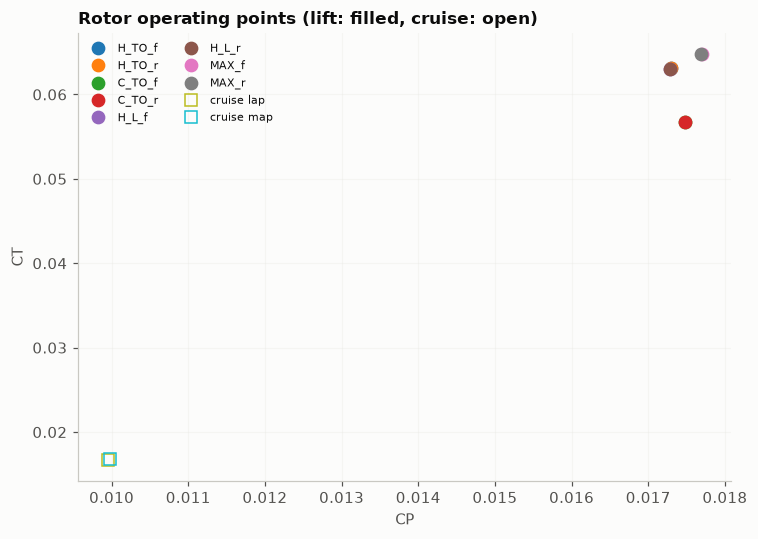

In [22]:
if have(BEST, "rotors", "R_m"):
    rho = rosella.RHO0
    fig, ax = plt.subplots(figsize=(7, 5))
    D = 2 * BEST["R_m"]
    for nm, r in BEST["rotors"].items():
        n = r["omega_rad_s"] / (2 * math.pi)
        ax.plot(r["P_shaft_W"] / (rho * n ** 3 * D ** 5), r["T_N"] / (rho * n ** 2 * D ** 4), "o", ms=8, label=nm)
    if "cruise" in BEST:
        Dc = rosella.cruise_diameter(ST)
        for k, r in BEST["cruise"].items():
            n = r["omega"] / (2 * math.pi)
            ax.plot(r["Q"] * r["omega"] / (rho * n ** 3 * Dc ** 5), r["thrust"] / (rho * n ** 2 * Dc ** 4), "s", ms=8, mfc="none", label="cruise " + k)
    else:
        note("The result file has no key `cruise`, so the cruise points are missing.")
    ax.set_xlabel("CP"); ax.set_ylabel("CT"); ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
    ax.set_title("Rotor operating points (lift: filled, cruise: open)")
    fig.tight_layout(); save(fig, "ct_cp"); plt.show()

## Step 7b. Lift blade check against Jung et al. 2021

Jung et al. 2021 (Unmanned Systems 9(4) 321-332, CC BY 4.0) scanned 22 off-the-shelf blades of 381 mm to 1016 mm.
The data file `data/jung2021_blades.csv` holds the T-motor chord and twist (read from Fig. 9 and Fig. 11) in SI.
The max-chord fit (Fig. 10) gives c_max = 0.0932 D + 2.418 mm. This is a check only. The blade does not change.
The FLUXER chord is a fitted model (fit to the maker thrust and power table), not measured geometry.

{'c_max_m': 0.04082421834821778, 'c_max_fit_m': 0.06396728061335845, 'c_max_ratio': 0.6382046877211216, 'r_at_c_max': 0.9241231209735147, 'reference': 'Tmotor_29'}
(0.25, 0.05881489709106362, 0.17991285572062113, -0.12109795862955751, 22.196266438805786, 15.884572777388822, 6.311693661416964)
(0.5, 0.0924077665186806, 0.188704860168341, -0.09629709364966041, 12.116512431023807, 10.964263607072217, 1.1522488239515898)
(0.75, 0.11622500779403457, 0.13817238362446074, -0.021947375830426177, 8.581368254730174, 8.100349983605104, 0.4810182711250697)
(0.95, 0.12255640157867861, 0.08450991039913114, 0.038046491179547476, 7.074179317737402, 5.800481478455672, 1.2736978392817297)


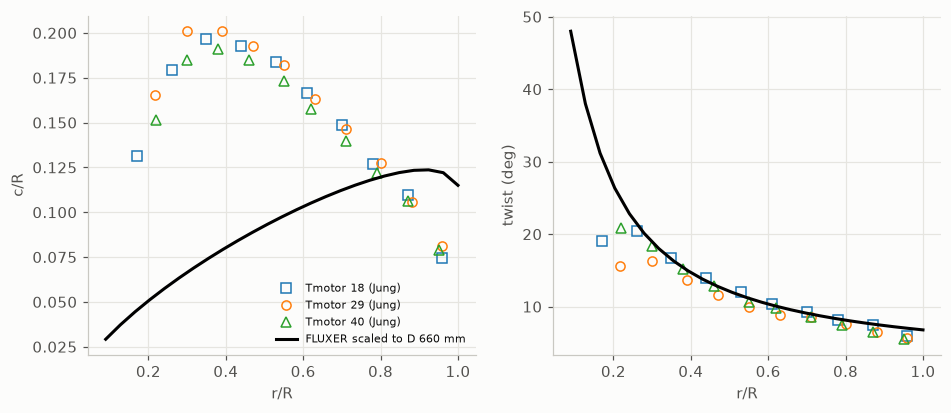

In [23]:
import jung2021 as J
# FLUXER state: c (m) and beta (rad) on 25 stations. r from R_hub 0.025 m (r_foils of the design) to R_tip.
FLUX = json.loads((rosella.WORK / "proptimiser" / "propellers" / "MAD_FLUXER_22x6_6.state.json").read_text())
R_REF_M = float(ST["proptimiser_reference_radius_m"])
D_M = BEST.get("D_m") or BEST["D_in"] * 0.0254
x = np.linspace(0.025, R_REF_M, len(FLUX["c"])) / R_REF_M
c = np.ravel(FLUX["c"]) * D_M / (2 * R_REF_M)
b = np.ravel(FLUX["beta"])
res = J.compare(x, c, b, D_M)
print({k: v for k, v in res.items() if k != "rows"})
for r in res["rows"]:
    print(r)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
J.plot_compare(a1, a2, x, c, b, D_M, f"FLUXER scaled to D {D_M * 1000:.0f} mm")
save(fig, "jung2021_check")


## Step 8. Boom margins and the 1P band

The margin is the fraction by which a constraint holds. Zero means the constraint is active. The stiffness rule is `f1 >= factor x f(1P at hover)`. The 1P band runs from the hover rpm to the full-throttle rpm of the same rotor.

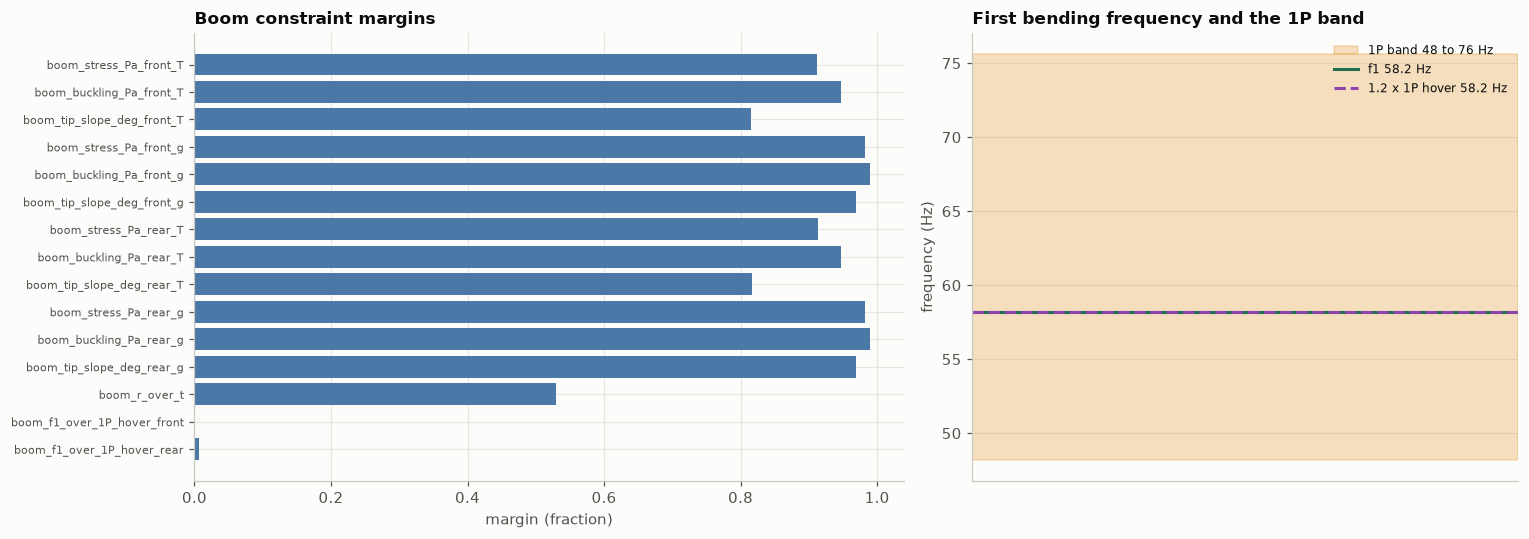

f1 is inside or below the 1P band. The rule only needs a factor times 1P at hover.


In [24]:
if have(BEST, "constraints", "f1_Hz", "rotors"):
    con = BEST["constraints"]
    keys = [k for k in con if k.startswith(("boom_stress", "boom_buckling", "boom_tip_slope", "boom_r_over_t", "boom_f1"))]
    mg = pd.Series({k: con[k]["margin"] for k in keys})
    fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
    ax[0].barh(mg.index[::-1], mg.values[::-1], color=["#c0392b" if v < 0 else "#4c78a8" for v in mg.values[::-1]])
    ax[0].set_xlabel("margin (fraction)"); ax[0].set_title("Boom constraint margins"); ax[0].tick_params(axis="y", labelsize=7)
    fh = {s: (BEST["rotors"]["H_TO_" + s]["rpm"] / 60, BEST["rotors"]["MAX_" + s]["rpm"] / 60) for s in ("f", "r")}
    lo, hi = min(v[0] for v in fh.values()), max(v[1] for v in fh.values())
    fac = rosella.val(ST["structure"], "stiffness_factor") if "stiffness_factor" in ST["structure"] else 1.2
    ax[1].axhspan(lo, hi, color="#e39b2f", alpha=0.3, label=f"1P band {lo:.0f} to {hi:.0f} Hz")
    ax[1].axhline(BEST["f1_Hz"], color="#1f6f50", lw=2, label=f"f1 {BEST['f1_Hz']:.1f} Hz")
    ax[1].axhline(fac * BEST["f_hover_1P_Hz"], color="#8e44ad", ls="--", label=f"{fac} x 1P hover {fac * BEST['f_hover_1P_Hz']:.1f} Hz")
    ax[1].set_xticks([]); ax[1].set_ylabel("frequency (Hz)"); ax[1].legend(fontsize=8); ax[1].set_title("First bending frequency and the 1P band")
    fig.tight_layout(); save(fig, "boom_margins"); plt.show()
    print("f1 is above the 1P band." if BEST["f1_Hz"] > hi else "f1 is inside or below the 1P band. The rule only needs a factor times 1P at hover.")

## Step 9. Control authority

The bars show the angular acceleration that the mixer gives at hover with each rotor inside its thrust limits. The red mark is the required value.

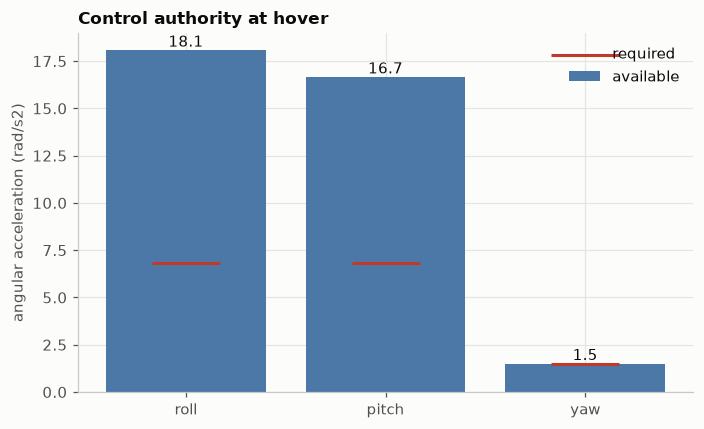

In [25]:
if have(BEST, "control", "constraints"):
    con = BEST["constraints"]; ctl = BEST["control"]
    ax_names = ["roll", "pitch", "yaw"]
    got = [ctl[k] for k in ax_names]
    req = [con[f"control_{k}_rad_s2"]["lo"] for k in ax_names]
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.bar(ax_names, got, color="#4c78a8", label="available")
    ax.scatter(ax_names, req, marker="_", s=2000, color="#c0392b", zorder=5, label="required")
    for k, v in enumerate(got):
        ax.text(k, v, f"{v:.1f}", ha="center", va="bottom")
    ax.set_ylabel("angular acceleration (rad/s2)"); ax.legend(); ax.set_title("Control authority at hover")
    fig.tight_layout(); save(fig, "control_authority"); plt.show()

## Step 10. Manual configuration window

Type your own parts. The window starts from the best case. **Evaluate** fixes every design variable and solves the model once. It shows a pass/fail table with a margin for each constraint. **Re-optimise booms** frees `t_boom` and `r_boom` only. It sizes the boom for your parts. **Save** writes a block to `rosella.manual.json` under the name you type. The command `python rosella.py evaluate NAME` reads this block.

How the inputs map to the model:

| Input | Model variable |
|---|---|
| motor kV | `kv` |
| motor Rm, I0, mass | `overrides.motor` |
| motor Imax | `q_cap = (Imax - I0) / kv_rad` (the torque that the motor holds at the peak current) |
| prop D (mm) | `scale = (D / 2) / 0.2794 m` |
| prop pitch (mm) | Not a model variable. The blade keeps its P/D. The value goes into the block as `inputs.prop_pitch_m` and into the order sheet. |
| prop mass, ESC mass, battery mass | `overrides.prop`, `.esc`, `.battery` |
| ESC A | The model limit `esc_current_A`: the ESC must carry 1.2 x the peak current. |
| battery S, P, Ah | `cells_s` and `cap_Ah = P x Ah` (Ah of one parallel string) |
| boom OD, ID, L | `r_boom`, `t_boom`, `a = (L - 2 x overhang) / 2` |
| boom y_b, dx | `y_b`, `dx` |
| boom E, rho | `inputs.boom_E_GPa` and `inputs.boom_rho_kg_m3`. `rosella.py evaluate` reads them too. |
| cant | `cant` (degrees in the window, radians in the file) |
| battery x | `x_batt` start value. The solver frees it (the CG equality needs it). |

In [26]:
import ipywidgets as W
from IPython.display import clear_output

MAT = ST["material"][ST["material"]["design_choice"]]
OVERHANG = rosella.val(ST["structure"], "overhang_m")
R_REF = float(ST["proptimiser_reference_radius_m"])
FREE_BOOMS = ["t_boom", "r_boom"]

def _num(v, desc, step=None, w="230px"):
    return W.FloatText(value=float(v), description=desc, step=step, layout=W.Layout(width=w), style={"description_width": "90px"})

def prefill(rep):
    d, n = rep["design"], rep["names"]
    kv_rad = d["kv"] * 2 * math.pi / 60
    D_m = rep["D_m"] if "D_m" in rep else 0.0254 * rep["D_in"]                    # old result files hold D_in
    bl = ST["proptimiser_blade"]
    pitch_m = rep["pitch_m"] if "pitch_m" in rep else bl["pitch_m"] / bl["diameter_m"] * D_m
    return dict(
        config=rep["config"], motor_kv=d["kv"], motor_rm=n["rm"], motor_i0=n["i0"], motor_mass=n["m_motor"],
        motor_imax=d["q_cap"] * kv_rad + n["i0"], prop_d=1000 * D_m, prop_pitch=1000 * pitch_m, prop_mass=n["m_prop"],
        esc_a=1.2 * n["I_pk"], esc_mass=n["m_esc"], bat_s=rep["cells_s"], bat_p=1, bat_ah=d["cap_Ah"], bat_mass=n["m_batt"],
        boom_od=2000 * d["r_boom"], boom_id=2000 * (d["r_boom"] - d["t_boom"]), boom_l=1000 * n["L_boom"], y_b=d["y_b"], dx=d["dx"],
        E=rosella.val(MAT, "E_axial_Pa") / 1e9, rho=rosella.val(MAT, "density_kg_m3"), cant=math.degrees(d["cant"]), x_batt=d["x_batt"])

P0 = prefill(BEST)
WID = {
    "config": W.Dropdown(options=["H4", "H8"], value=P0["config"], description="config", layout=W.Layout(width="230px")),
    "motor_kv": _num(P0["motor_kv"], "motor kV"), "motor_rm": _num(P0["motor_rm"], "motor Rm (ohm)", 0.005),
    "motor_i0": _num(P0["motor_i0"], "motor I0 (A)", 0.1), "motor_mass": _num(P0["motor_mass"], "motor mass (kg)", 0.01),
    "motor_imax": _num(P0["motor_imax"], "motor Imax (A)", 1.0),
    "prop_d": _num(P0["prop_d"], "prop D (mm)", 5), "prop_pitch": _num(P0["prop_pitch"], "prop pitch (mm)", 2),
    "prop_mass": _num(P0["prop_mass"], "prop mass (kg)", 0.005),
    "esc_a": _num(P0["esc_a"], "ESC (A)", 1.0), "esc_mass": _num(P0["esc_mass"], "ESC mass (kg)", 0.005),
    "bat_s": W.IntText(value=int(P0["bat_s"]), description="battery S", layout=W.Layout(width="230px"), style={"description_width": "90px"}),
    "bat_p": W.IntText(value=int(P0["bat_p"]), description="battery P", layout=W.Layout(width="230px"), style={"description_width": "90px"}),
    "bat_ah": _num(P0["bat_ah"], "Ah per string", 0.5), "bat_mass": _num(P0["bat_mass"], "battery mass (kg)", 0.1),
    "boom_od": _num(P0["boom_od"], "boom OD (mm)", 0.5), "boom_id": _num(P0["boom_id"], "boom ID (mm)", 0.5),
    "boom_l": _num(P0["boom_l"], "boom L (mm)", 10), "y_b": _num(P0["y_b"], "y_b (m)", 0.01), "dx": _num(P0["dx"], "dx (m)", 0.01),
    "E": _num(P0["E"], "boom E (GPa)", 1.0), "rho": _num(P0["rho"], "boom rho (kg/m3)", 10),
    "cant": _num(P0["cant"], "cant (deg)", 0.5), "x_batt": _num(P0["x_batt"], "battery x (m)", 0.01),
}
LEVEL = W.Dropdown(options=["L4", "L3", "L2"], value="L4", description="level", layout=W.Layout(width="230px"))
FREE = W.Checkbox(value=False, description="save with free booms (free: t_boom, r_boom)", indent=False, layout=W.Layout(width="auto"))
NAME = W.Text(value="my_config", description="save as", layout=W.Layout(width="300px"))
B_EVAL = W.Button(description="Evaluate", button_style="primary")
B_REOPT = W.Button(description="Re-optimise booms", button_style="warning")
B_SAVE = W.Button(description="Save", button_style="success")
LOG = W.Output()

def set_inputs(p):
    for k, v in p.items():
        WID[k].value = v

def values():
    return {k: w.value for k, w in WID.items()}

def to_block(v):
    """The window inputs as a block of rosella.manual.json (the format of rosella.evaluate)."""
    kv_rad = v["motor_kv"] * 2 * math.pi / 60
    r_o, r_i = v["boom_od"] / 2000, v["boom_id"] / 2000
    fixed = {"t_boom": r_o - r_i, "r_boom": r_o, "y_b": v["y_b"], "dx": v["dx"], "a": (v["boom_l"] / 1000 - 2 * OVERHANG) / 2,
             "scale": (v["prop_d"] / 1000 / 2) / R_REF, "kv": v["motor_kv"], "q_cap": (v["motor_imax"] - v["motor_i0"]) / kv_rad,
             "cant": math.radians(v["cant"]), "cap_Ah": v["bat_p"] * v["bat_ah"], "x_batt": v["x_batt"]}
    return {"config": v["config"], "cells_s": int(v["bat_s"]), "fixed": fixed,
            "overrides": {"motor": {"mass_kg": v["motor_mass"], "rm_ohm": v["motor_rm"], "i0_A": v["motor_i0"]},
                          "prop": {"mass_kg": v["prop_mass"]}, "esc": {"mass_kg": v["esc_mass"]}, "battery": {"mass_kg": v["bat_mass"]}},
            "free": FREE_BOOMS if FREE.value else [],
            "inputs": {"prop_pitch_m": v["prop_pitch"] / 1000, "esc_A": v["esc_a"], "motor_imax_A": v["motor_imax"], "battery_P": v["bat_p"],
                       "battery_Ah_per_string": v["bat_ah"], "boom_E_GPa": v["E"], "boom_rho_kg_m3": v["rho"]}}

def solve_block(block, v=None, free=None, level="L4", name="nb_manual"):
    """The same function as rosella.py evaluate: rosella.evaluate_block. The block holds E, rho, the ESC current and the pitch
    (inputs). x_batt is free by default. The files go to work/aerosandbox/rosella/lab/manual."""
    return rosella.evaluate_block(block, ST, OUT / "manual", level, name=name, free=free, air=AIR, motor=MOTOR)

def check_table(rep, v=None):
    rows = []
    for k, c in rep["constraints"].items():
        if not c["enabled"]:
            continue
        rows.append({"constraint": k, "group": c["group"], "value": c["value"], "lo": c["lo"], "hi": c["hi"], "margin": c["margin"],
                     "result": "PASS" if rosella.passes(c) else "FAIL"})
    return pd.DataFrame(rows)

def style_table(df):
    def colour(r):
        return ["background-color: #f4c7c3" if r["result"] == "FAIL" else "" for _ in r]
    return df.style.apply(colour, axis=1).format({c: "{:.4g}" for c in ("value", "lo", "hi", "margin")}, na_rep="")

LAST = {}
def show_result(rep, v, title):
    tbl = check_table(rep, v)
    LAST.update(rep=rep, table=tbl)
    d, n = rep["design"], rep["names"]
    print(f"{title}: converged {rep['converged']}, {rep['status'].get('return_status')}, ok {rep['ok']}, {rep['seconds']:.0f} s")
    if rosella.indicative_note(rep):
        print(rosella.indicative_note(rep))
    print(f"mass {n['M']:.2f} kg, mission energy {rep['energy_total_Wh']:.0f} Wh, peak current {n['I_pk']:.1f} A, "
          f"boom OD {2000 * d['r_boom']:.1f} mm, ID {2000 * (d['r_boom'] - d['t_boom']):.1f} mm, f1 {rep['f1_Hz']:.1f} Hz")
    nfail = int((tbl["result"] == "FAIL").sum())
    print(f"{nfail} constraint(s) fail" if nfail else "all constraints pass")
    if not rep["converged"]:
        print("The solver did not converge. The numbers are from the last iterate and may not be reliable.")
    display(style_table(tbl))

def on_evaluate(_=None):
    with LOG:
        clear_output(wait=True)
        v = values(); block = to_block(v); block["free"] = []
        rep = solve_block(block, v, free=[], level=LEVEL.value, name="nb_evaluate")
        show_result(rep, v, "Evaluate")

def on_reopt(_=None):
    with LOG:
        clear_output(wait=True)
        v = values(); block = to_block(v)
        rep = solve_block(block, v, free=FREE_BOOMS, level=LEVEL.value, name="nb_reoptimise")
        show_result(rep, v, "Re-optimise booms")
        d = rep["design"]
        print(f"New boom: OD {2000 * d['r_boom']:.2f} mm, ID {2000 * (d['r_boom'] - d['t_boom']):.2f} mm. Press 'Use boom' to copy it to the window.")
        use = W.Button(description="Use boom", button_style="info")
        def _use(_):
            WID["boom_od"].value, WID["boom_id"].value = 2000 * d["r_boom"], 2000 * (d["r_boom"] - d["t_boom"])
        use.on_click(_use); display(use)

def on_save(_=None):
    with LOG:
        name = NAME.value.strip()
        if not name:
            print("Type a name first."); return
        blocks = json.loads(MANUAL.read_text(encoding="utf-8")) if MANUAL.exists() else {}
        blocks[name] = to_block(values())
        MANUAL.write_text(json.dumps(blocks, indent=1), encoding="utf-8")
        print(f"Saved block '{name}' to {MANUAL}. Run: python rosella.py evaluate {name}")

B_EVAL.on_click(on_evaluate); B_REOPT.on_click(on_reopt); B_SAVE.on_click(on_save)
col = lambda *ks: W.VBox([WID[k] for k in ks])
display(W.VBox([
    W.HBox([col("config", "bat_s", "bat_p", "bat_ah", "bat_mass"), col("motor_kv", "motor_rm", "motor_i0", "motor_mass", "motor_imax"),
            col("prop_d", "prop_pitch", "prop_mass", "esc_a", "esc_mass")]),
    W.HBox([col("boom_od", "boom_id", "boom_l", "y_b"), col("dx", "E", "rho", "cant", "x_batt")]),
    W.HBox([LEVEL, FREE]), W.HBox([B_EVAL, B_REOPT, NAME, B_SAVE]), LOG]))

## Step 11. Test: the Redback parts on the Rosella airframe

The parts are the ones in `aircraft/redback`: MAD M6C10 IPE V3 KV150, MAD FLUXER 22x6.6, AMPX 40A and a 12S3P pack of 4.5 Ah cells (3.786 kg). The prop mass and the ESC mass are stand-ins with no source: 75 g and 85 g. The boom, y_b, dx, cant and battery x come from the best case. This cell calls the same function as the Evaluate button. The prop is 558.8 mm (22 in) with a pitch of 167.6 mm (6.6 in).

In [27]:
set_inputs(dict(config="H4", motor_kv=150, motor_rm=0.12, motor_i0=0.7, motor_mass=0.234, motor_imax=36.3,
                prop_d=22.0 * 25.4, prop_pitch=6.6 * 25.4, prop_mass=0.075, esc_a=40.0, esc_mass=0.085,
                bat_s=12, bat_p=3, bat_ah=4.5, bat_mass=3.786))
on_evaluate()
# The Output widget keeps its text in the widget state. Print the same numbers to the cell output as well.
r = LAST["rep"]
print("converged", r["converged"], r["status"].get("return_status"), "| M", round(r["names"]["M"], 2), "kg | E", round(r["energy_total_Wh"]), "Wh | I_pk", round(r["names"]["I_pk"], 1), "A")
print(LAST["table"].to_string(index=False, float_format=lambda x: f"{x:.4g}"))

converged False Infeasible_Problem_Detected | M 14.71 kg | E 369 Wh | I_pk 33.3 A
                 constraint     group     value     lo        hi     margin result
                    mtow_kg      mass     14.71    NaN        15    0.01966   PASS
                     cg_x_m        cg    0.1391 0.1391    0.1391 -1.995e-16   PASS
            tip_mach_H_TO_f        tw     90.44    NaN     221.2     0.5911   PASS
            tip_mach_H_TO_r        tw     90.44    NaN     221.2     0.5911   PASS
            tip_mach_C_TO_f        tw     126.9    NaN     221.2     0.4263   PASS
            tip_mach_C_TO_r        tw     126.1    NaN     221.2     0.4299   PASS
             tip_mach_H_L_f        tw     119.2    NaN     221.2     0.4611   PASS
             tip_mach_H_L_r        tw     118.5    NaN     221.2     0.4645   PASS
             tip_mach_MAX_f        tw     183.2    NaN     221.2     0.1719   PASS
             tip_mach_MAX_r        tw     183.2    NaN     221.2     0.1719   PASS
     

In [28]:
# The block that the Save button would write (printed only, nothing goes to the source tree here).
blk = to_block(values())
print(json.dumps({k: blk[k] for k in ("config", "cells_s", "fixed", "overrides", "free")}, indent=1))

{
 "config": "H4",
 "cells_s": 12,
 "fixed": {
  "t_boom": 0.000999999990318988,
  "r_boom": 0.02822477733676942,
  "y_b": 0.47020000353265917,
  "dx": -0.05230368771731129,
  "a": 0.5605496381654285,
  "scale": 1.0,
  "kv": 150.0,
  "q_cap": 2.2663663896285895,
  "cant": 0.06493576790487622,
  "cap_Ah": 13.5,
  "x_batt": -0.18803726355200656
 },
 "overrides": {
  "motor": {
   "mass_kg": 0.234,
   "rm_ohm": 0.12,
   "i0_A": 0.7
  },
  "prop": {
   "mass_kg": 0.075
  },
  "esc": {
   "mass_kg": 0.085
  },
  "battery": {
   "mass_kg": 3.786
  }
 },
 "free": []
}


## Skipped plots
The cell below lists every note that a skipped plot raised.

In [29]:
print("\n".join(MISSING) if MISSING else "No plot was skipped for a missing key.")
print("Plots in", OUT)

No plot was skipped for a missing key.
Plots in C:\Users\AQUAGUY\Documents\GitHub\Aeroplan\work\aerosandbox\rosella\lab
